In [1]:
#! ai aided cell to help me fix some import path issues I didnt understand
import sys
from pathlib import Path

root = Path.cwd()
if root.name == "src":
    root = root.parent

if not (root / "src" / "models" / "ViTV1.py").is_file():
    raise RuntimeError(f"Not at the repository root: {root}")

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

In [2]:
import torch
from src.models.ViTV1 import ViT_V1
from src.train import Checkpoint, load_checkpoint
from src.dataset import TODataset, Mode
from pathlib import Path
from src.utils import visualize, reshape_distribution, preprocess

In [3]:
Path.cwd()

WindowsPath('c:/Users/lucas/Desktop/Uni/Lernen/Master/5. Semester/Applied Deep Learning/12435611_topology-optimization/src')

In [4]:
# load data

dataset = TODataset(Path("./../data/labeled_data/test"), patch_size=8)

INFO:src.dataset:Initializing Dataset with path ..\data\labeled_data\test
INFO:src.dataset:Dataset: n_samples 3000
INFO:src.dataset:Dataset initialized succesfully


In [52]:
# load model

path = Path.cwd() / "../trainings/ViT_V1_e4_q2_b1_h2_p8/adam_0.001_bce/epoch_100.pth"
checkpoint: Checkpoint = load_checkpoint(path)
model_state_dict = checkpoint.model_state_dict
model = ViT_V1(
    embedding_dims=checkpoint.model_spec.embedding_dims,
    query_dims=checkpoint.model_spec.query_dims,
    n_attention_blocks=checkpoint.model_spec.n_attention_blocks,
    n_attention_heads=checkpoint.model_spec.n_attention_heads,
    patch_size=checkpoint.model_spec.patch_size,
)
model.load_state_dict(checkpoint.model_state_dict)
model.eval()  # set the model to evaluation mode

INFO:root:Loading checkpoint from c:\Users\lucas\Desktop\Uni\Lernen\Master\5. Semester\Applied Deep Learning\12435611_topology-optimization\src\..\trainings\ViT_V1_e4_q2_b1_h2_p8\adam_0.001_bce\epoch_100.pth


ViT_V1(
  (linear_patch): Linear(in_features=64, out_features=4, bias=True)
  (linear_param): Linear(in_features=261, out_features=4, bias=True)
  (readout): Linear(in_features=260, out_features=4096, bias=True)
  (linear_vs): ModuleList(
    (0): Linear(in_features=4, out_features=4, bias=True)
  )
  (linear_qs): ModuleList(
    (0): Linear(in_features=4, out_features=2, bias=True)
  )
  (linear_ks): ModuleList(
    (0): Linear(in_features=4, out_features=2, bias=True)
  )
  (linears): ModuleList(
    (0): Linear(in_features=4, out_features=4, bias=True)
  )
)

True density shape: torch.Size([4096])
Predicted density shape: torch.Size([4096])
Stress shape: torch.Size([4096])


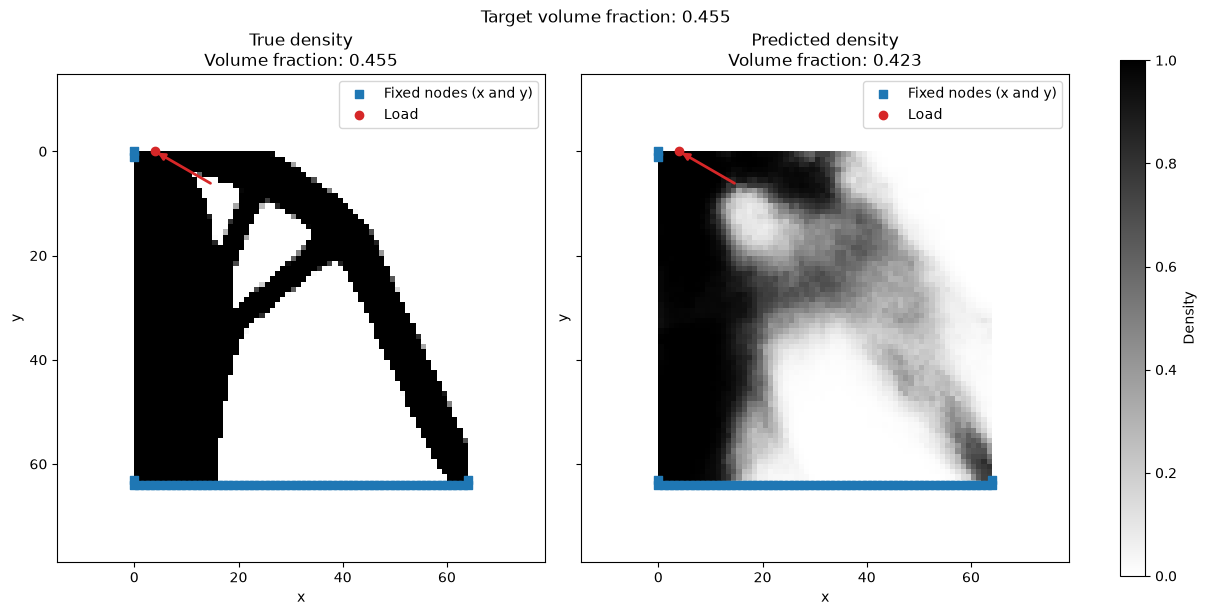

(<Figure size 1200x600 with 3 Axes>,
 array([<Axes: title={'center': 'True density\nVolume fraction: 0.455'}, xlabel='x', ylabel='y'>,
        <Axes: title={'center': 'Predicted density\nVolume fraction: 0.423'}, xlabel='x', ylabel='y'>],
       dtype=object))

In [53]:
from src.utils import orientation_angle


sample_idx =  14 # 13 # 10
# todo: check 103 -> data
sample = dataset[sample_idx]
volume_fraction = sample[0][0]
load = sample[0][1:5]
bcs = sample[0][5:5+4*64]
stress = sample[0][5+4*64:]

true_density = sample[1]

# # preprocessing the sample

# angle = orientation_angle(load)

# sample = preprocess(volume_fraction, load, bcs, stress, checkpoint.model_spec.patch_size)
with torch.no_grad():
    predicted_density = model(sample[0].unsqueeze(0)).squeeze(0)

# round to 1 or 0
# predicted_density = (predicted_density > 0.5).float()

print("True density shape:", true_density.shape)
print("Predicted density shape:", predicted_density.shape)
print("Stress shape:", stress.shape)

stress = stress
true_density = true_density
with torch.no_grad():
    predicted_density = predicted_density


visualize(
    true_density,
    predicted_density,
    load=load,
    bcs=bcs,
    volume_fraction=volume_fraction
)



In [48]:
with torch.no_grad():
    p = model(sample[0].unsqueeze(0))[0]
    logits = torch.logit(p.clamp(1e-6, 1 - 1e-6))
    stray = (p > 0.95) & (sample[1] < 0.05)
    print("stray pixels:", stray.sum().item(),
          "| logits min/median:", logits[stray].min().item(), logits[stray].median().item())

stray pixels: 85 | logits min/median: 2.9775161743164062 4.077902317047119
